[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LucaswasTaken/Openhardware-hpc/blob/master/notebooks/Aula1_CPU.ipynb)

# Aula 1 — Paralelismo e desempenho na CPU
### Computação de Alto Desempenho em Python para Engenharia Civil

| Tempo | Bloco |
|---|---|
| 0:00–0:20 | 1. Medir antes de otimizar |
| 0:20–0:50 | 2. Speedup, eficiência, Amdahl e Gustafson |
| 0:50–1:30 | 3. Threads × processos, o GIL e o Python sem GIL |
| 1:30–1:45 | ☕ Intervalo |
| 1:45–2:30 | 4. Vetorização, BLAS e `joblib` |
| 2:30–3:10 | 5. Numba: compilando o laço |
| 3:10–3:30 | 6. Exercício guiado e lista de exercícios |

**Como usar:** rode as células em ordem (Shift+Enter). Todo resultado medido é guardado em `results/`, e os gráficos dos slides e dos vídeos usam esses números.

> No Colab gratuito a máquina tem **2 núcleos**. O speedup máximo de CPU fica perto de 2× — e isso é uma lição, não um defeito: o limite é o hardware. Em casa ou no laboratório, rode de novo e compare.

In [1]:
# Preparação: bibliotecas, informações da máquina e registro de resultados
import json, os, sys, time, platform, pathlib, datetime
import numpy as np
import matplotlib.pyplot as plt

NO_COLAB = "google.colab" in sys.modules
if NO_COLAB:
    %pip install -q line_profiler threadpoolctl

NUCLEOS = os.cpu_count()
MAQUINA = "colab" if NO_COLAB else "local"
print(f"Python {platform.python_version()} · NumPy {np.__version__} · {NUCLEOS} núcleos lógicos · {platform.processor() or platform.machine()}")

RESULTADOS = {"maquina": MAQUINA, "nucleos": NUCLEOS, "python": platform.python_version(),
              "data": datetime.date.today().isoformat()}

def registrar(chave, **valores):
    """Guarda um resultado medido em results/aula1_<maquina>.json (usado pelos slides e vídeos)."""
    RESULTADOS[chave] = valores
    pasta = pathlib.Path("results"); pasta.mkdir(exist_ok=True)
    (pasta / f"aula1_{MAQUINA}.json").write_text(json.dumps(RESULTADOS, indent=1, ensure_ascii=False), encoding="utf-8")
    return valores

def cronometro(f, *args, repeticoes=3, **kw):
    """Menor tempo de várias execuções (o menor é o mais próximo do custo real, sem ruído)."""
    melhores = []
    for _ in range(repeticoes):
        t = time.perf_counter(); f(*args, **kw); melhores.append(time.perf_counter() - t)
    return min(melhores)

Python 3.12.13 · NumPy 2.4.6 · 12 núcleos lógicos · Intel64 Family 6 Model 186 Stepping 3, GenuineIntel


## 1. Medir antes de otimizar  ·  0:00–0:20
> 🎬 **Vídeo (2 min):** [Por que paralelizar e como medir](https://lucaswastaken.github.io/Openhardware-hpc/#v01)

Uma simulação de engenharia típica é **muitas contas independentes**: casos de carga, posições de um veículo, amostras de Monte Carlo, elementos de uma malha. Antes de paralelizar, precisamos saber **onde o tempo vai**. Regra de ouro: *não otimize o que você não mediu*.

**Exemplo:** linha de influência — o momento fletor no meio de uma viga biapoiada (vão $L$) para uma carga $P$ passando em $n$ posições, avaliado em $m$ seções.

In [2]:
def momento(x, a, L, P=1.0):
    """Momento na seção x de uma viga biapoiada com carga P na posição a."""
    if x <= a:
        return P * (L - a) * x / L
    return P * a * (L - x) / L

def envoltoria_python(L=30.0, n_cargas=1500, n_secoes=1500):
    """Máximo momento em cada seção para todas as posições da carga — dois laços em Python puro."""
    secoes = [L * i / (n_secoes - 1) for i in range(n_secoes)]
    cargas = [L * j / (n_cargas - 1) for j in range(n_cargas)]
    return [max(momento(x, a, L) for a in cargas) for x in secoes]

t = time.perf_counter()
env = envoltoria_python()
print(f"perf_counter: {time.perf_counter() - t:.3f} s   (momento máximo = {max(env):.2f} P·m, esperado PL/4 = {30/4:.2f})")

perf_counter: 0.301 s   (momento máximo = 7.50 P·m, esperado PL/4 = 7.50)


In [3]:
# %timeit repete a medida e mostra média ± desvio — bom para trechos curtos
%timeit -n 1 -r 3 envoltoria_python()

282 ms ± 11.9 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


**Onde está o tempo?** O `cProfile` conta chamadas de função; o `line_profiler` mede linha a linha.

In [4]:
import cProfile, pstats
cProfile.run("envoltoria_python()", "perfil.out")
pstats.Stats("perfil.out").sort_stats("cumulative").print_stats(5);

Sat Oct 31 16:01:02 2026    perfil.out

         4503026 function calls (4503023 primitive calls) in 1.175 seconds

   Ordered by: cumulative time
   List reduced from 23 to 5 due to restriction <5>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      2/1    0.000    0.000    1.174    1.174 {built-in method builtins.exec}
        1    0.001    0.001    1.174    1.174 <string>:1(<module>)
1502/1500    0.281    0.000    1.171    0.001 {built-in method builtins.max}
        1    0.002    0.002    0.962    0.962 C:\Users\lucas\AppData\Local\Temp\ipykernel_31520\2295421989.py:7(envoltoria_python)
  2251500    0.586    0.000    0.890    0.000 C:\Users\lucas\AppData\Local\Temp\ipykernel_31520\2295421989.py:11(<genexpr>)




In [5]:
%load_ext line_profiler
%lprun -f envoltoria_python envoltoria_python(n_cargas=300, n_secoes=300)

O tempo está nas **2,25 milhões de chamadas** de `momento` — todas independentes entre si. Isso é **paralelismo de dados**: a mesma conta em dados diferentes. Primeiro passo: deixar o NumPy fazer o laço (em C).

In [6]:
def envoltoria_numpy(L=30.0, n_cargas=1500, n_secoes=1500):
    x = np.linspace(0, L, n_secoes)[:, None]   # seções (coluna)
    a = np.linspace(0, L, n_cargas)[None, :]   # posições da carga (linha)
    M = np.where(x <= a, (L - a) * x / L, a * (L - x) / L)
    return M.max(axis=1)

t_py = cronometro(envoltoria_python, repeticoes=1)
t_np = cronometro(envoltoria_numpy)
assert np.allclose(envoltoria_numpy(), envoltoria_python())
print(f"Python puro: {t_py:.3f} s · NumPy: {t_np*1e3:.2f} ms · {t_py/t_np:.0f}× mais rápido, no mesmo núcleo")
registrar("envoltoria", python_s=t_py, numpy_s=t_np)

Python puro: 0.316 s · NumPy: 30.26 ms · 10× mais rápido, no mesmo núcleo


{'python_s': 0.3163520998787135, 'numpy_s': 0.03025870001874864}

> **Lição 1:** antes de usar vários núcleos, use bem **um** núcleo. Vetorizar costuma render mais que paralelizar.

**🧠 Teste rápido**
1. Por que usamos o *menor* tempo de várias repetições, e não o primeiro?
2. O `cProfile` mostrou milhões de chamadas de `momento`. O que isso sugere sobre onde atacar?

## 2. Speedup, eficiência, Amdahl e Gustafson  ·  0:20–0:50
> 🎬 **Vídeo (2 min):** [Speedup, eficiência e lei de Amdahl](https://lucaswastaken.github.io/Openhardware-hpc/#v02)

| Métrica | Fórmula | Leitura |
|---|---|---|
| Speedup | $S(p) = T_1 / T_p$ | quantas vezes mais rápido com $p$ núcleos |
| Eficiência | $E(p) = S(p)/p$ | fração do hardware bem usada (1 = perfeito) |
| Lei de Amdahl | $S(p) = \dfrac{1}{(1-f) + f/p}$ | problema **fixo**: a parte serial $(1-f)$ limita tudo |
| Lei de Gustafson | $S(p) = (1-f) + f\,p$ | problema **cresce** com $p$: o speedup escala |

- **Escalabilidade forte (strong scaling):** mesmo problema, mais núcleos → o tempo cai? (Amdahl)
- **Escalabilidade fraca (weak scaling):** problema cresce junto com os núcleos → o tempo fica constante? (Gustafson)

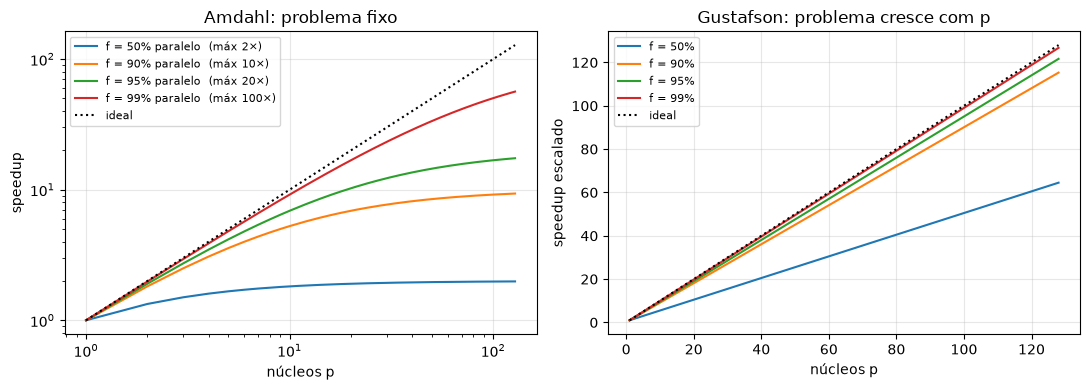

In [7]:
p = np.arange(1, 129)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for f in (0.50, 0.90, 0.95, 0.99):
    ax1.plot(p, 1 / ((1 - f) + f / p), label=f"f = {f:.0%} paralelo  (máx {1/(1-f):.0f}×)")
    ax2.plot(p, (1 - f) + f * p, label=f"f = {f:.0%}")
ax1.plot(p, p, "k:", label="ideal")
ax1.set(title="Amdahl: problema fixo", xlabel="núcleos p", ylabel="speedup", xscale="log", yscale="log")
ax2.plot(p, p, "k:", label="ideal")
ax2.set(title="Gustafson: problema cresce com p", xlabel="núcleos p", ylabel="speedup escalado")
for ax in (ax1, ax2): ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**✍️ Miniexercício (5 min).** Uma análise estrutural levou 120 s em 1 núcleo, 34 s em 4 e 21 s em 8.
1. Calcule speedup e eficiência para 4 e 8 núcleos.
2. Use a **métrica de Karp–Flatt**, $e = \dfrac{1/S - 1/p}{1 - 1/p}$, para estimar a fração serial. Ela fica constante? Se cresce com $p$, o problema é *overhead* (comunicação, sincronização), não só a parte serial.

In [8]:
T = {1: 120.0, 4: 34.0, 8: 21.0}
for p_, t_ in T.items():
    if p_ == 1: continue
    S = T[1] / t_; E = S / p_; e = (1/S - 1/p_) / (1 - 1/p_)
    print(f"p={p_}: speedup {S:.2f}×  eficiência {E:.0%}  fração serial estimada {e:.1%}")

p=4: speedup 3.53×  eficiência 88%  fração serial estimada 4.4%
p=8: speedup 5.71×  eficiência 71%  fração serial estimada 5.7%


## 3. Threads × processos, o GIL e o Python sem GIL  ·  0:50–1:30
> 🎬 **Vídeo (3 min):** [Threads × processos, GIL e Python sem GIL](https://lucaswastaken.github.io/Openhardware-hpc/#v03)

- **Thread:** várias linhas de execução no **mesmo** processo, compartilhando memória. Leves.
- **Processo:** cópia independente do interpretador, com **memória própria**. Mais pesado (criar, enviar dados), mas isolado.
- **GIL (Global Interpreter Lock):** no CPython tradicional, só **uma thread executa bytecode Python por vez**. Threads ajudam em espera (rede, disco) e em código que solta o GIL (NumPy, BLAS), mas **não** em laços Python puros.
- **Novidade:** desde o Python 3.13 existe a versão *free-threaded* (`python3.13t`, `python3.14t`), **sem GIL** — oficialmente suportada a partir do 3.14 (PEP 779). Vamos medir.

In [9]:
import threading

def trabalho(n=3_000_000):
    """Laço Python puro (CPU-bound)."""
    s = 0
    for i in range(n):
        s += i * i
    return s

def com_threads(alvo, k):
    ts = [threading.Thread(target=alvo) for _ in range(k)]
    for t_ in ts: t_.start()
    for t_ in ts: t_.join()

K = 4
t_serial = cronometro(lambda: [trabalho() for _ in range(K)], repeticoes=1)
t_thr = cronometro(com_threads, trabalho, K, repeticoes=1)
print(f"CPU-bound, {K} tarefas: serial {t_serial:.2f} s · {K} threads {t_thr:.2f} s → speedup {t_serial/t_thr:.2f}× (GIL!)")

espera = lambda: time.sleep(0.5)   # simula leitura de arquivo/rede
t_io_serial = cronometro(lambda: [espera() for _ in range(K)], repeticoes=1)
t_io_thr = cronometro(com_threads, espera, K, repeticoes=1)
print(f"Espera (I/O), {K} tarefas: serial {t_io_serial:.2f} s · {K} threads {t_io_thr:.2f} s → speedup {t_io_serial/t_io_thr:.2f}×")
registrar("threads_gil", cpu_serial_s=t_serial, cpu_threads_s=t_thr, io_serial_s=t_io_serial, io_threads_s=t_io_thr)

CPU-bound, 4 tarefas: serial 0.79 s · 4 threads 0.70 s → speedup 1.12× (GIL!)


Espera (I/O), 4 tarefas: serial 2.00 s · 4 threads 0.50 s → speedup 3.99×


{'cpu_serial_s': 0.7860015998594463,
 'cpu_threads_s': 0.7043739000800997,
 'io_serial_s': 2.002265099901706,
 'io_threads_s': 0.5012286000419408}

### 3.1 Processos: Monte Carlo para confiabilidade estrutural

Probabilidade de falha de um elemento: $P_f = P(R < S)$, com resistência $R$ (lognormal) e solicitação $S$ (Gumbel, carga máxima anual). Sem fórmula fechada simples → **Monte Carlo**: sorteie milhões de pares $(R, S)$ e conte quantas vezes $R < S$. Cada lote de amostras é **independente** → ideal para processos.

> **Por que um arquivo `.py`?** No Windows e no macOS, processos novos são criados do zero (*spawn*) e precisam **importar** a função. Funções definidas só no notebook não são encontradas. Gravar os *workers* num módulo funciona em todo lugar.

In [10]:
%%writefile workers_aula1.py
import numpy as np

def lote_falhas(args):
    """Conta falhas (R < S) num lote de n amostras com semente própria."""
    n, semente = args
    rng = np.random.default_rng(semente)
    R = rng.lognormal(mean=np.log(350.0), sigma=0.10, size=n)    # resistência [kN·m]
    S = rng.gumbel(loc=200.0, scale=25.0, size=n)                # solicitação máxima [kN·m]
    return int(np.count_nonzero(R < S))

Overwriting workers_aula1.py


In [11]:
from concurrent.futures import ProcessPoolExecutor
from workers_aula1 import lote_falhas

N_TOTAL = 160_000_000
def monte_carlo(processos, lotes=64):
    tarefas = [(N_TOTAL // lotes, 1000 + i) for i in range(lotes)]
    if processos == 1:
        falhas = sum(map(lote_falhas, tarefas))
    else:
        with ProcessPoolExecutor(max_workers=processos) as ex:
            falhas = sum(ex.map(lote_falhas, tarefas))
    return falhas / N_TOTAL

tempos = {}
for p_ in sorted({1, 2, 4, NUCLEOS} & set(range(1, NUCLEOS + 1))):
    t = time.perf_counter(); pf = monte_carlo(p_); tempos[p_] = time.perf_counter() - t
    print(f"{p_:>2} processos: {tempos[p_]:.2f} s   Pf = {pf:.2e}   speedup {tempos[1]/tempos[p_]:.2f}×  eficiência {tempos[1]/tempos[p_]/p_:.0%}")
registrar("monte_carlo_processos", tempos={str(k): v for k, v in tempos.items()}, pf=pf)

 1 processos: 7.10 s   Pf = 5.48e-03   speedup 1.00×  eficiência 100%


 2 processos: 4.07 s   Pf = 5.48e-03   speedup 1.75×  eficiência 87%


 4 processos: 2.98 s   Pf = 5.48e-03   speedup 2.38×  eficiência 60%


12 processos: 3.17 s   Pf = 5.48e-03   speedup 2.24×  eficiência 19%


{'tempos': {'1': 7.099971400108188,
  '2': 4.067086100112647,
  '4': 2.9824642001185566,
  '12': 3.1703019000124186},
 'pf': 0.00548411875}

O speedup não chega a $p$: criar processos, enviar tarefas e juntar resultados custa tempo (*overhead*) — e no Colab só há 2 núcleos físicos.

### 3.2 Python sem GIL (3.14t)

O mesmo laço com threads, agora em dois interpretadores: Python 3.14 normal e Python 3.14**t** (*free-threaded*). Usamos o `uv` para baixar os dois sem mexer no Python do Colab.

In [12]:
%%writefile gil_demo.py
import sys, threading, time

def trabalho(n=3_000_000):
    s = 0
    for i in range(n):
        s += i * i
    return s

K = 4
t = time.perf_counter(); [trabalho() for _ in range(K)]; serial = time.perf_counter() - t
ts = [threading.Thread(target=trabalho) for _ in range(K)]
t = time.perf_counter(); [x.start() for x in ts]; [x.join() for x in ts]; par = time.perf_counter() - t
gil = sys._is_gil_enabled() if hasattr(sys, "_is_gil_enabled") else True
print(f"{sys.version.split()[0]:<8} GIL {'ligado ' if gil else 'DESLIGADO'}  serial {serial:5.2f} s  {K} threads {par:5.2f} s  speedup {serial/par:4.2f}×")

Overwriting gil_demo.py


In [13]:
import shutil, subprocess
if not shutil.which("uv"):
    %pip install -q uv
uv = shutil.which("uv") or "uv"
subprocess.run([uv, "python", "install", "-q", "3.14", "3.14t"], check=True)
saidas = {}
for versao in ("3.14", "3.14t"):
    r = subprocess.run([uv, "run", "--no-project", "--python", versao, "gil_demo.py"], capture_output=True, text=True,
                       encoding="utf-8", env={**os.environ, "PYTHONIOENCODING": "utf-8"})
    print(r.stdout.strip() or r.stderr[-400:])
    saidas[versao] = r.stdout.strip()
registrar("python_sem_gil", **saidas)

3.14.6   GIL ligado   serial  0.54 s  4 threads  0.55 s  speedup 0.98×


3.14.6   GIL DESLIGADO  serial  0.57 s  4 threads  0.22 s  speedup 2.63×


{'3.14': '3.14.6   GIL ligado   serial  0.54 s  4 threads  0.55 s  speedup 0.98×',
 '3.14t': '3.14.6   GIL DESLIGADO  serial  0.57 s  4 threads  0.22 s  speedup 2.63×'}

> **Lição 3:** sem GIL, threads Python finalmente usam vários núcleos. Mas: bibliotecas precisam ser compatíveis, o código serial fica um pouco mais lento, e **corridas de dados** (duas threads escrevendo na mesma variável) passam a ser problema seu. Para cálculo numérico, NumPy/Numba/GPU continuam sendo o caminho principal.

**🧠 Teste rápido**
1. Por que threads aceleraram a *espera* mas não o laço?
2. Por que o speedup com processos foi menor que o número de processos?
3. O que muda (e o que não muda) com o Python 3.14t?

---
## ☕ Intervalo · 1:30–1:45

## 4. Vetorização, BLAS e `joblib`  ·  1:45–2:30
> 🎬 **Vídeo (2 min):** [joblib: estudo paramétrico em 3 linhas](https://lucaswastaken.github.io/Openhardware-hpc/#v05)

Operações de álgebra linear do NumPy (`@`, `solve`) chamam o **BLAS/LAPACK** (OpenBLAS ou MKL), que **já é paralelo** com threads. Ou seja: às vezes você já está usando todos os núcleos sem saber. O `threadpoolctl` mostra e controla isso.

In [14]:
from threadpoolctl import threadpool_info, threadpool_limits
info = threadpool_info()
print([(i["internal_api"], i["num_threads"]) for i in info])

A = np.random.default_rng(0).random((2000, 2000))
with threadpool_limits(limits=1):
    t1 = cronometro(lambda: A @ A)
tN = cronometro(lambda: A @ A)
print(f"A @ A (2000×2000): 1 thread {t1:.3f} s · todas {tN:.3f} s → {t1/tN:.2f}×  ({2*2000**3/tN/1e9:.0f} GFLOP/s)")
registrar("blas_matmul", t_1thread=t1, t_todas=tN, gflops=2*2000**3/tN/1e9)

[('openblas', 12)]


A @ A (2000×2000): 1 thread 0.472 s · todas 0.125 s → 3.78×  (128 GFLOP/s)


{'t_1thread': 0.4718531998805702,
 't_todas': 0.12489729980006814,
 'gflops': 128.10525147951415}

### 4.1 Estudo paramétrico com `joblib`

Projeto preliminar: para cada combinação de **vão**, **altura da seção** e **carga**, resolva a viga por elementos finitos (Euler–Bernoulli) e verifique a flecha ($L/250$). São milhares de análises independentes — o caso clássico de *"embaraçosamente paralelo"*.

In [15]:
%%writefile viga_mef.py
import numpy as np

def flecha_maxima(L, h, q, b=0.20, E=30e9, n_el=200):
    """Viga biapoiada, carga distribuída q [N/m], seção b×h [m], MEF com elementos de Euler–Bernoulli."""
    I = b * h**3 / 12
    le = L / n_el
    k = E * I / le**3 * np.array([[12, 6*le, -12, 6*le], [6*le, 4*le**2, -6*le, 2*le**2],
                                  [-12, -6*le, 12, -6*le], [6*le, 2*le**2, -6*le, 4*le**2]])
    fe = q * le / 12 * np.array([6, le, 6, -le])
    ndof = 2 * (n_el + 1)
    K = np.zeros((ndof, ndof)); F = np.zeros(ndof)
    for e in range(n_el):
        idx = slice(2 * e, 2 * e + 4)
        K[idx, idx] += k; F[idx] += fe
    livres = np.setdiff1d(np.arange(ndof), [0, ndof - 2])      # apoios: deslocamento nulo nas pontas
    u = np.zeros(ndof)
    u[livres] = np.linalg.solve(K[np.ix_(livres, livres)], F[livres])
    return float(np.abs(u[0::2]).max())

def verifica(caso):
    L, h, q = caso
    w = flecha_maxima(L, h, q)
    return L, h, q, w, w <= L / 250

Overwriting viga_mef.py


In [16]:
from itertools import product
from joblib import Parallel, delayed, parallel_config
from viga_mef import verifica, flecha_maxima

# conferência com a solução analítica 5qL⁴/384EI
L, h, q = 8.0, 0.6, 20e3
print(f"MEF {flecha_maxima(L, h, q)*1e3:.3f} mm · analítico {5*q*L**4/(384*30e9*0.2*h**3/12)*1e3:.3f} mm")

casos = list(product(np.linspace(4, 12, 16), np.linspace(0.3, 1.0, 15), np.linspace(10e3, 40e3, 4)))
print(f"{len(casos)} análises")

with threadpool_limits(limits=1):          # cada análise usa 1 thread de BLAS (evita sobreassinatura)
    t_serial = cronometro(lambda: [verifica(c) for c in casos], repeticoes=1)
    tempos_jl = {}
    for n in sorted({2, 4, NUCLEOS} & set(range(2, NUCLEOS + 1))):
        with parallel_config(backend="loky", inner_max_num_threads=1):
            t = time.perf_counter(); res = Parallel(n_jobs=n)(delayed(verifica)(c) for c in casos)
            tempos_jl[n] = time.perf_counter() - t
        print(f"joblib n_jobs={n:>2}: {tempos_jl[n]:.2f} s → speedup {t_serial/tempos_jl[n]:.2f}×")
print(f"serial: {t_serial:.2f} s · {sum(r[4] for r in res)} de {len(res)} vigas passam na flecha L/250")
registrar("joblib_vigas", serial_s=t_serial, tempos={str(k): v for k, v in tempos_jl.items()}, casos=len(casos))

MEF 9.877 mm · analítico 9.877 mm
960 análises


joblib n_jobs= 2: 3.02 s → speedup 1.69×


joblib n_jobs= 4: 2.10 s → speedup 2.43×


joblib n_jobs=12: 2.58 s → speedup 1.98×
serial: 5.11 s · 757 de 960 vigas passam na flecha L/250


{'serial_s': 5.110305899986997,
 'tempos': {'2': 3.0167155999224633,
  '4': 2.104429099941626,
  '12': 2.5785428998060524},
 'casos': 960}

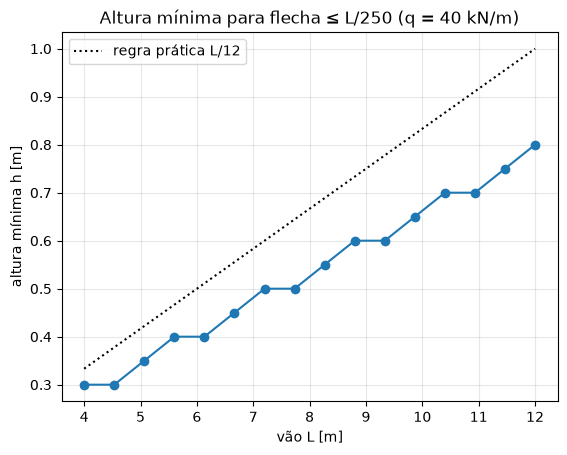

In [17]:
# Resultado de engenharia: menor altura que atende L/250 para cada vão (carga máxima)
import collections
menor = collections.defaultdict(lambda: np.inf)
for L_, h_, q_, w_, ok in res:
    if ok and q_ == max(c[2] for c in casos):
        menor[L_] = min(menor[L_], h_)
Ls = sorted(menor)
plt.plot(Ls, [menor[x] for x in Ls], "o-"); plt.plot(Ls, np.array(Ls) / 12, "k:", label="regra prática L/12")
plt.xlabel("vão L [m]"); plt.ylabel("altura mínima h [m]"); plt.legend(); plt.grid(alpha=.3)
plt.title("Altura mínima para flecha ≤ L/250 (q = 40 kN/m)"); plt.show()

> **Sobreassinatura (oversubscription):** 4 processos × 4 threads de BLAS = 16 threads disputando 4 núcleos → fica *mais lento*. Por isso limitamos o BLAS a 1 thread dentro de cada processo (`inner_max_num_threads=1`).

**🧠 Teste rápido**
1. Por que `A @ A` ficou mais rápido sem mudarmos nada no código?
2. Quando vale paralelizar com `joblib` em vez de vetorizar?

## 5. Numba: compilando o laço  ·  2:30–3:10
> 🎬 **Vídeo (2 min):** [Numba: do laço lento ao código compilado](https://lucaswastaken.github.io/Openhardware-hpc/#v06)

Nem tudo vetoriza bem: laços com `if`, acumulações, malhas. O **Numba** compila funções Python para código de máquina (via LLVM) na primeira chamada (*just-in-time*). Com `parallel=True` e `prange`, distribui o laço entre os núcleos — com **threads de verdade**, porque o código compilado não precisa do GIL.

**Exemplo:** matriz de rigidez de uma treliça plana com milhões de barras — para cada barra, a matriz local 4×4 $k = \frac{EA}{L}\begin{bmatrix} c^2 & cs & -c^2 & -cs\\ & s^2 & -cs & -s^2 \\ & & c^2 & cs \\ \text{sim.} & & & s^2\end{bmatrix}$.

In [18]:
from numba import njit, prange, get_num_threads

def gera_trelica(n_barras, seed=0):
    rng = np.random.default_rng(seed)
    n_nos = n_barras // 2 + 2
    xy = rng.random((n_nos, 2)) * 100
    conect = np.column_stack([rng.integers(0, n_nos, n_barras), rng.integers(0, n_nos, n_barras)])
    conect[conect[:, 0] == conect[:, 1], 1] = (conect[conect[:, 0] == conect[:, 1], 0] + 1) % n_nos
    return xy, conect, np.full(n_barras, 200e9 * 1e-3)   # E·A [N]

def rigidez_python(xy, conect, EA):
    k = np.empty((len(conect), 4, 4))
    for e in range(len(conect)):
        i, j = conect[e]
        dx, dy = xy[j] - xy[i]
        L = (dx * dx + dy * dy) ** 0.5
        c, s = dx / L, dy / L
        v = np.array([-c, -s, c, s])
        k[e] = EA[e] / L * np.outer(v, v)
    return k

def rigidez_numpy(xy, conect, EA):
    d = xy[conect[:, 1]] - xy[conect[:, 0]]
    L = np.hypot(d[:, 0], d[:, 1])
    v = np.column_stack([-d, d]) / L[:, None]
    return (EA / L)[:, None, None] * v[:, :, None] * v[:, None, :]

@njit(cache=True)
def rigidez_numba(xy, conect, EA):
    n = conect.shape[0]
    k = np.empty((n, 4, 4))
    for e in range(n):
        i, j = conect[e, 0], conect[e, 1]
        dx = xy[j, 0] - xy[i, 0]; dy = xy[j, 1] - xy[i, 1]
        L = (dx * dx + dy * dy) ** 0.5
        v = (-dx / L, -dy / L, dx / L, dy / L)
        f = EA[e] / L
        for a in range(4):
            for b in range(4):
                k[e, a, b] = f * v[a] * v[b]
    return k

@njit(parallel=True, fastmath=True, cache=True)
def rigidez_numba_par(xy, conect, EA):
    n = conect.shape[0]
    k = np.empty((n, 4, 4))
    for e in prange(n):                      # cada barra numa thread diferente
        i, j = conect[e, 0], conect[e, 1]
        dx = xy[j, 0] - xy[i, 0]; dy = xy[j, 1] - xy[i, 1]
        L = (dx * dx + dy * dy) ** 0.5
        v = (-dx / L, -dy / L, dx / L, dy / L)
        f = EA[e] / L
        for a in range(4):
            for b in range(4):
                k[e, a, b] = f * v[a] * v[b]
    return k

In [19]:
xy, conect, EA = gera_trelica(2_000_000)
pequeno = slice(0, 100_000)

t = time.perf_counter(); rigidez_numba(xy[:10], conect[:2] % 10, EA[:2]); t_comp = time.perf_counter() - t
print(f"1ª chamada do Numba (compilação ou cache): {t_comp:.2f} s")
rigidez_numba_par(xy, conect, EA)            # aquece a versão paralela

t_py = cronometro(rigidez_python, xy, conect[pequeno], EA[pequeno], repeticoes=1) * 20   # extrapolado para 2 M
t_np = cronometro(rigidez_numpy, xy, conect, EA)
t_nb = cronometro(rigidez_numba, xy, conect, EA)
t_nbp = cronometro(rigidez_numba_par, xy, conect, EA)
assert np.allclose(rigidez_numpy(xy, conect, EA), rigidez_numba_par(xy, conect, EA))
for nome, t_ in [("Python puro (extrapolado)", t_py), ("NumPy vetorizado", t_np), ("Numba 1 núcleo", t_nb),
                 (f"Numba paralelo ({get_num_threads()} threads)", t_nbp)]:
    print(f"{nome:<30} {t_:8.3f} s   {t_py/t_:7.0f}× vs Python")
registrar("numba_trelica", python_s=t_py, numpy_s=t_np, numba_s=t_nb, numba_par_s=t_nbp, threads=get_num_threads())

1ª chamada do Numba (compilação ou cache): 1.32 s


Python puro (extrapolado)        28.247 s         1× vs Python
NumPy vetorizado                  0.712 s        40× vs Python
Numba 1 núcleo                    0.180 s       157× vs Python
Numba paralelo (12 threads)       0.039 s       725× vs Python


{'python_s': 28.24704600032419,
 'numpy_s': 0.7120755999349058,
 'numba_s': 0.18048600014299154,
 'numba_par_s': 0.03893590020015836,
 'threads': 12}

In [20]:
# Montagem da matriz global esparsa a partir das matrizes locais (COO → CSR)
from scipy.sparse import coo_matrix
k = rigidez_numba_par(xy, conect, EA)
gl = np.column_stack([2*conect[:, 0], 2*conect[:, 0]+1, 2*conect[:, 1], 2*conect[:, 1]+1])
lin = np.repeat(gl, 4, axis=1).ravel(); col = np.tile(gl, (1, 4)).ravel()
t = time.perf_counter()
K = coo_matrix((k.ravel(), (lin, col)), shape=(2*len(xy),)*2).tocsr()
print(f"K global: {K.shape[0]:,} GDL, {K.nnz:,} não nulos, montada em {time.perf_counter()-t:.2f} s")

K global: 2,000,004 GDL, 19,926,556 não nulos, montada em 1.48 s


> **Lição 5:** NumPy é ótimo quando a conta cabe em operações de array; o Numba brilha em **laços com lógica**, sem criar arrays temporários, e paraleliza com `prange`. Atenção: a 1ª chamada compila (use `cache=True`), e `prange` exige iterações **independentes** (cuidado com somas na mesma posição — use reduções).

**🧠 Teste rápido**
1. Por que o Numba paralelo usa threads e mesmo assim não sofre com o GIL?
2. Por que não usamos `prange` na montagem global (`K[i, j] += ...`)?

## 6. Exercício guiado e lista de exercícios  ·  3:10–3:30
> 🎬 **Vídeo (2 min):** [Como fazer o relatório: speedup, eficiência e gráficos](https://lucaswastaken.github.io/Openhardware-hpc/#v11)

**Tarefa (10 min):** num pórtico com 1 milhão de seções, cada seção tem esforços $N$, $M$ e área/módulo $A$, $W$. A tensão máxima é $\sigma = |N|/A + |M|/W$. Conte quantas seções passam de $f_y = 250$ MPa e encontre a maior tensão. Acelere a versão em Python puro com a ferramenta que preferir e meça o speedup.

In [21]:
rng = np.random.default_rng(42)
n = 1_000_000
N = rng.normal(0, 400e3, n); M = rng.normal(0, 150e3, n)            # N [N], M [N·m]
A = rng.uniform(4e-3, 1.2e-2, n); W = rng.uniform(4e-4, 1.5e-3, n)   # A [m²], W [m³]

def verifica_python(N, M, A, W, fy=250e6):
    excedem, sig_max = 0, 0.0
    for i in range(len(N)):
        s = abs(N[i]) / A[i] + abs(M[i]) / W[i]
        if s > fy: excedem += 1
        if s > sig_max: sig_max = s
    return excedem, sig_max

t_ref = cronometro(verifica_python, N, M, A, W, repeticoes=1)
print(f"Python puro: {t_ref:.2f} s → {verifica_python(N, M, A, W)}")

# TODO: escreva sua versão aqui (NumPy? Numba com prange e reduções?) e compare.

Python puro: 0.57 s → (244300, np.float64(1839649013.4165308))


In [22]:
# 💡 Solução (tente antes de olhar!)
def verifica_numpy(N, M, A, W, fy=250e6):
    s = np.abs(N) / A + np.abs(M) / W
    return int(np.count_nonzero(s > fy)), float(s.max())

@njit(parallel=True)
def verifica_numba(N, M, A, W, fy=250e6):
    excedem, sig_max = 0, 0.0
    for i in prange(len(N)):                     # o Numba reconhece += e max como reduções
        s = abs(N[i]) / A[i] + abs(M[i]) / W[i]
        excedem += s > fy
        sig_max = max(sig_max, s)
    return excedem, sig_max

verifica_numba(N[:10], M[:10], A[:10], W[:10])
for nome, f in [("NumPy", verifica_numpy), ("Numba paralelo", verifica_numba)]:
    t_ = cronometro(f, N, M, A, W)
    print(f"{nome:<15} {t_*1e3:7.1f} ms → {t_ref/t_:6.0f}×   {f(N, M, A, W)}")

NumPy              14.5 ms →     39×   (244300, 1839649013.4165308)
Numba paralelo      1.1 ms →    532×   (244300, 1839649013.4165308)


### Lista de exercícios
Escolha **um** exercício de [`exercicios/lista.md`](../exercicios/lista.md) e **uma** tecnologia. Use o [modelo de relatório](../exercicios/modelo_relatorio.ipynb): ele já mede tempo, speedup e eficiência e gera os gráficos.

### Resumo da Aula 1
| Ferramenta | Quando usar | Cuidado |
|---|---|---|
| NumPy | contas em arrays inteiros | arrays temporários grandes |
| BLAS (via NumPy) | álgebra linear densa | já é paralelo — não sobreassine |
| `ProcessPoolExecutor` / `multiprocessing` | tarefas independentes e pesadas | overhead de criar processos e enviar dados; worker em `.py` |
| `joblib` | estudos paramétricos, laços independentes | limite as threads internas |
| Numba (`@njit`, `prange`) | laços com lógica, malhas | compilação na 1ª chamada; iterações independentes |
| Threads | espera (I/O); Python 3.14t | GIL no Python tradicional |

**Próxima aula:** GPU — milhares de núcleos, memória separada (ou não?) e a equação do calor.